# Estadificación del sueño con DART y CRNN

Clasificación retrospectiva de épocas de 30 segundos en Sleep-Telemetry y Sleep-Cassette. La evaluación reserva personas completas de ambas cohortes. La combinación utiliza un LightGBM DART y una CRNN espectral contextual; ambos predicen las mismas cinco etapas. El ajuste final y la exportación con las 100 personas se realizan en [otro notebook](dart_crnn_mixto_final_100.ipynb).

### Hiperparámetros de LightGBM

DART usa **666 iteraciones** con una tasa de aprendizaje de **0,03**. Cada árbol tiene hasta **36 hojas**, profundidad máxima **8** y un mínimo de **25 segmentos por hoja**.

| Parámetro | Valor del modelo |
| --- | --- |
| Muestreo por iteración | 80 % de los segmentos y 60 % de las características |
| Regularización | L1 = 0,1, L2 = 1,5 |
| Descarte de árboles en DART | `drop_rate` = 0,1, `skip_drop` = 0,5 |
| Pesos por etapa | N1 = 2,2, N2 = 0,41, N3 = 1,56, REM = 1,0, W = 2,01 |
| Semilla | 42 |

### Arquitectura de la CRNN contextual

La red procesa **15 segmentos consecutivos de 30 segundos** (7,5 minutos). La convolución identifica patrones dentro de cada segmento y la GRU bidireccional usa los segmentos anteriores y posteriores de la ventana para estimar la etapa de sueño.

| Capa | Configuración y función |
| --- | --- |
| Entrada | 15 segmentos × 6 bloques de 5 s × 96 características. Las características combinan la potencia por banda de los dos EEG, el EOG y el EMG con su normalización y su contexto temporal. |
| Convolución por segmento | Conv1D con 48 filtros de ancho 3 y activación ReLU. Recorre los seis bloques y conserva una salida por bloque. |
| Resumen del segmento | Se aplanan las 6 × 48 salidas y una capa densa con ReLU las reduce a 48 valores. Dropout del 15 %. |
| Contexto entre segmentos | GRU bidireccional con 32 unidades por dirección. Las dos direcciones aportan 64 valores por segmento. Dropout del 20 %. |
| Salida | Una capa densa con softmax produce cinco probabilidades por segmento, una para cada etapa (N1, N2, N3, REM y W). |

**Entrenamiento.** Adam con tasa de aprendizaje 0,001, 27 épocas, lotes de 64 secuencias y semilla 42. En inferencia se combinan tres ventanas solapadas mediante una media geométrica. La distribución resultante se combina con la de DART utilizando la proporción seleccionada en el experimento de fusión.

La selección de hiperparámetros utilizó las mismas 20 personas que el informe. DART alcanzó su mayor F1 en la iteración 666 de 667 y la CRNN en la época 27 de 400. Las métricas describen el desempeño en el grupo utilizado para seleccionar la configuración.

## Configuración de la corrida

`MODO_AJUSTE = "solo_crnn"` carga el DART de 666 iteraciones y entrena la CRNN desde cero durante 27 épocas. Para reproducir el informe con ambos modelos guardados, usa `"cargar"`. La opción `"ambos"` entrena ambas ramas y guarda cada corrida en una carpeta nueva en `datos/experimentos/dart_crnn_mixto/<versión>/reajustes/`.

In [1]:
import hashlib
import inspect
import json
import os
import sys
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
from uuid import uuid4

os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "5")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import lightgbm as lgb
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.fft import rfft
from scipy.ndimage import convolve1d
from scipy.special import softmax
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / ".dvc/config").is_file())
SRC = ROOT / "packages/sleep-staging/src"
sys.path.insert(0, str(SRC))
from sleep_staging.inference.mixed_bundle import read_training_manifest, save_mixed_manifest, stage_mixed_bundle
from sleep_staging import PreprocessingConfig, PreprocessingPipeline
from sleep_staging.datasets import (
    discover_sleep_cassette_records,
    discover_sleep_telemetry_records,
)
from sleep_staging.training import create_lightgbm_classifier, load_or_build_supervised_dataset

MODO_AJUSTE = "solo_crnn"
DATA = ROOT / "datos"
VERSION = "dart_666_crnn_27_20261119_191036"
EXPERIMENTO = DATA / "experimentos/dart_crnn_mixto" / VERSION
STORE = DATA
if MODO_AJUSTE == "ambos":
    STORE = EXPERIMENTO / "reajustes" / uuid4().hex
    print(f"Carpeta para el nuevo ajuste: {STORE.relative_to(ROOT)}")
PESO_DART = 0.70  # Referencia inicial. La celda de predicciones lee la mezcla seleccionada.
SPEC = json.loads((DATA / "experimentos/lightgbm_st_sc/experimento.json").read_text("utf8"))
CLASES = np.array(SPEC["classes"])
COLUMNAS = SPEC["feature_columns"]
PERFILES = {c: SPEC["preprocessing_" + c.lower()] for c in ("Telemetry", "Cassette")}
CANALES = PERFILES["Telemetry"]["channels"]
ITERACIONES_DART = 666
PARAMS = dict(SPEC["parameters"], n_jobs=6, n_estimators=ITERACIONES_DART)
BANDAS = [(0.3, 4), (4, 8), (8, 12), (12, 16), (16, 30), (30, 35)]
DESFASES = (0, 5, 10)
SEMILLA = 42
EPOCAS_CRNN = 27
tf.config.experimental.enable_op_determinism()

## Funciones del experimento

Estas celdas definen el preprocesamiento, el ajuste y la evaluación. La ejecución con los datos comienza en **Datos y partición por persona**.

## DART

El paquete del proyecto prepara las características tabulares y construye el clasificador. La configuración mixta conserva el orden de sus 2.280 columnas y sus pesos por etapa. Las características de EMG no disponibles en Cassette se representan como valores ausentes.

In [2]:
def entrenar_dart(filas):
    """Ajusta DART sobre las filas de entrenamiento en el orden de columnas publicado."""
    modelo = create_lightgbm_classifier(**PARAMS)

    def progreso(env):
        iteracion = env.iteration + 1
        if iteracion % 50 == 0 or iteracion == env.end_iteration:
            print(f"DART · {iteracion}/{env.end_iteration} iteraciones", flush=True)

    datos = X if filas.index.equals(X.index) else X.loc[filas.index]
    modelo.fit(datos, filas.etapa, callbacks=[progreso])
    if not np.array_equal(modelo.classes_, CLASES):
        raise ValueError("El orden de etapas de DART difiere del orden publicado.")
    return modelo.booster_

## CRNN contextual

La rama neuronal usa dos EEG, EOG y EMG. Después del filtro de 0,3–35 Hz y la normalización por época, cada segmento produce seis bloques de cinco segundos y seis bandas por canal. Se añaden la escala robusta de la noche y dos ventanas de contexto (7,5 y 2 minutos). La red combina convolución y GRU bidireccional sobre secuencias de 15 épocas. Las etiquetas de relleno y las épocas sin anotación se excluyen de la pérdida.

In [3]:
def entrada_crnn(archivo_edf):
    with mne.io.read_raw_edf(archivo_edf, preload=True, verbose='ERROR') as raw:
        if raw.info['sfreq'] != 100:
            raise ValueError('La CRNN requiere una señal a 100 Hz.')
        presentes = [c for c in CANALES if c in raw.ch_names]
        if not set(CANALES[:3]).issubset(presentes):
            raise ValueError(f'Faltan señales EEG/EOG en {archivo_edf.name}')
        raw.pick(presentes).filter(.3, 35., verbose=False)
        n = raw.n_times // 3000
        signal = np.zeros((n, 3000, 4), dtype='float32')
        for j, ch in enumerate(CANALES):
            if ch in presentes:
                v = raw.get_data(picks=[ch], stop=n*3000).reshape(n, 3000)*1e6
                signal[:,:,j] = (v-v.mean(1,keepdims=True))/(v.std(1,keepdims=True)+1e-8)
    f = np.fft.rfftfreq(500, 1/100)
    ventana = np.hanning(500).astype('float32')[None,None,:,None]
    x = np.empty((n, 6, 24), dtype='float32')
    for i in range(0,n,100):
        bloque = signal[i:i+100].reshape(-1,6,500,4)
        potencia = np.abs(rfft(bloque*ventana, axis=2))**2/500
        x[i:i+len(bloque)] = np.concatenate([
            np.log1p(potencia[:,:,(f>=a)&(f<b)].mean(axis=2)) for a,b in BANDAS], axis=-1)
    q10, mediana, q90 = np.percentile(x.reshape(-1,24), [10,50,90], axis=0)
    z = np.clip((x-mediana)/np.maximum(q90-q10,.05),-5,5).astype('float32')
    media = z.mean(axis=1)
    triangular = np.r_[1:9,7:0:-1].astype('float32')
    centro = convolve1d(media, triangular/triangular.sum(), axis=0, mode='nearest')
    pad = np.pad(media,((3,0),(0,0)),mode='edge')
    pasado = sum(pad[i:i+n] for i in range(4))/4
    return np.concatenate([x,z,np.broadcast_to(centro[:,None],x.shape),
                           np.broadcast_to(pasado[:,None],x.shape)],axis=-1)

In [4]:
def bloques(x, desfase, relleno=0):
    """Agrupa una noche en secuencias de 15 épocas e incorpora el relleno de los extremos."""
    pad = [(desfase, -(len(x) + desfase) % 15)] + [(0, 0)] * (x.ndim - 1)
    return np.pad(x, pad, constant_values=relleno).reshape(-1, 15, *x.shape[1:])


def entrenar_crnn(filas, entradas):
    """Entrena desde cero con las noches indicadas, alternando el desfase en cada época."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    rng = np.random.default_rng(SEMILLA)
    capas = tf.keras.layers
    entrada = capas.Input((15, 6, 96))
    z = capas.TimeDistributed(capas.Conv1D(48, 3, padding="same", activation="relu"))(entrada)
    z = capas.TimeDistributed(capas.Flatten())(z)
    z = capas.Dropout(0.15)(capas.Dense(48, activation="relu")(z))
    z = capas.Bidirectional(capas.GRU(32, return_sequences=True))(z)
    red = tf.keras.Model(entrada, capas.Dense(5, activation="softmax")(capas.Dropout(0.20)(z)))
    red.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="sparse_categorical_crossentropy")
    conteos = filas.etapa.value_counts().reindex(CLASES).to_numpy()
    pesos = (conteos.mean() / conteos) ** 0.35
    pesos /= np.average(pesos, weights=conteos)
    lotes = {}
    for d in DESFASES:
        xs, ys = [], []
        for rid, g in filas.groupby("record_id"):
            y = np.full(len(entradas[rid]), -1, dtype="int32")
            y[g.epoch_index] = pd.Categorical(g.etapa, categories=CLASES).codes
            y = bloques(y, d, -1)
            valido = (y >= 0).any(1)
            xs.append(bloques(entradas[rid], d)[valido])
            ys.append(y[valido])
        x, y = np.concatenate(xs), np.concatenate(ys)
        lotes[d] = (x, y.clip(0), np.where(y >= 0, pesos[y.clip(0)], 0).astype("float32"))
    for epoca in range(EPOCAS_CRNN):
        x, y, w = lotes[DESFASES[epoca % 3]]
        orden = rng.permutation(len(x))
        red.fit(
            x[orden],
            y[orden],
            sample_weight=w[orden],
            batch_size=64,
            epochs=1,
            shuffle=False,
            verbose=0,
        )
        if (epoca + 1) % 5 == 0 or epoca + 1 == EPOCAS_CRNN:
            print(f"CRNN · {epoca + 1}/{EPOCAS_CRNN} épocas", flush=True)
    return red


def prob_crnn(red, x):
    """Combina las tres vistas temporales para obtener probabilidades por época."""
    vistas = []
    for d in DESFASES:
        v = red.predict(bloques(x, d), batch_size=128, verbose=0).reshape(-1, len(CLASES))
        vistas.append(v[d : d + len(x)].astype("float64"))
    return softmax(np.log(np.maximum(vistas, 1e-10)).mean(axis=0), axis=1)

## Fusión y persistencia

La combinación utiliza una media geométrica de las probabilidades de DART y CRNN. Cada fila conserva el orden N1, N2, N3, REM y W. La referencia asigna 70 % a DART y 30 % a CRNN. El experimento de fusión compara 101 proporciones en las mismas 20 personas y guarda la elegida con el F1 macro y las huellas de los dos modelos.

In [5]:
def combinar(p_dart, p_crnn, peso_dart):
    """Combina las probabilidades de las cinco etapas mediante una media geométrica ponderada."""
    if p_dart.shape != p_crnn.shape:
        raise ValueError("Las probabilidades de ambas ramas deben estar alineadas.")
    if not 0 <= peso_dart <= 1:
        raise ValueError("El peso de DART debe estar entre 0 y 1.")
    peso_crnn = round(1 - peso_dart, 12)
    return softmax(
        peso_dart * np.log(np.maximum(p_dart, 1e-7))
        + peso_crnn * np.log(np.maximum(p_crnn, 1e-7)),
        axis=1,
    )


def metricas(g, modelos):
    """Calcula F1 macro, exactitud y kappa de cada modelo para las filas indicadas."""
    return pd.DataFrame(
        [
            [
                f1_score(g.etapa, g[m], labels=CLASES, average="macro", zero_division=0),
                accuracy_score(g.etapa, g[m]),
                cohen_kappa_score(g.etapa, g[m]),
            ]
            for m in modelos
        ],
        index=modelos,
        columns=["F1 macro", "Exactitud", "Kappa"],
    )


def leer_mezcla_seleccionada(ficha_80, obligatoria):
    """Recupera la proporción evaluada para las huellas exactas de ambas ramas."""
    ruta = EXPERIMENTO / "fusion.json"
    if ruta.is_file():
        seleccion = json.loads(ruta.read_text("utf8"))
        huellas_modelos = {k: v["sha256"] for k, v in ficha_80["archivos"].items()}
        if (
            seleccion["version"] == VERSION
            and seleccion["iteraciones_dart"] == ITERACIONES_DART
            and seleccion["epocas_crnn"] == EPOCAS_CRNN
            and seleccion["sha256_pesos"] == huellas_modelos
        ):
            return seleccion
    if obligatoria:
        raise ValueError(
            "Se requiere una selección de mezcla verificada sobre los modelos 80/20 de esta versión."
        )
    return None

### Caché espectral e integridad de archivos

In [6]:
def sha256(path):
    """Calcula la huella SHA-256 de un archivo sin cargarlo completo en memoria."""
    with path.open("rb") as f:
        return (
            hashlib.file_digest(f, "sha256").hexdigest()
            if hasattr(hashlib, "file_digest")
            else digest_stream(f)
        )


def digest_stream(f):
    """Calcula SHA-256 por bloques en versiones de Python anteriores a 3.11."""
    h = hashlib.sha256()
    for chunk in iter(lambda: f.read(2**20), b""):
        h.update(chunk)
    return h.hexdigest()


def huella_json(obj):
    """Identifica un contrato a partir de su representación JSON ordenada."""
    return hashlib.sha256(
        json.dumps(obj, sort_keys=True, ensure_ascii=False).encode()
    ).hexdigest()


def carpeta_espectral():
    """Localiza la caché correspondiente a esta receta espectral y sus dependencias."""
    receta_entrada = {
        "codigo": inspect.getsource(entrada_crnn),
        "canales": list(CANALES),
        "bandas": BANDAS,
        "versiones": {p: version(p) for p in ("mne", "numpy", "scipy")},
    }
    contenido = json.dumps(receta_entrada, sort_keys=True, ensure_ascii=False)
    clave = hashlib.sha256(contenido.encode("utf8")).hexdigest()[:16]
    carpeta = DATA / "processed" / "crnn_espectral" / clave
    carpeta.mkdir(parents=True, exist_ok=True)
    receta_path = carpeta / "preprocesamiento.json"
    if not receta_path.exists():
        temp = carpeta / (uuid4().hex + ".tmp")
        temp.write_text(contenido, encoding="utf8")
        temp.replace(receta_path)
    return carpeta


def entrada_espectral_guardada(archivo, huella, carpeta, calculada=None):
    """Carga la entrada espectral de una noche y la calcula si falta en la caché."""
    ruta = carpeta / f"{archivo.stem}-{huella}.npy"
    if not ruta.is_file():
        valores = entrada_crnn(archivo) if calculada is None else calculada
        temporal = carpeta / (uuid4().hex + ".npy")
        try:
            np.save(temporal, valores, allow_pickle=False)
            temporal.replace(ruta)
        finally:
            temporal.unlink(missing_ok=True)
    resultado = np.load(ruta, mmap_mode="r", allow_pickle=False)
    if resultado.dtype != np.float32 or resultado.ndim != 3 or resultado.shape[1:] != (6, 96):
        raise ValueError(f"Entrada espectral incompatible en {ruta}")
    return resultado

### Carga y guardado de modelos

In [7]:
def contrato(filas):
    """Describe los datos, el preprocesamiento y la configuración del entrenamiento."""
    return {
        "receta": receta,
        "paquete": paquete,
        "versiones": versiones,
        "registros_entrenamiento": {r: huellas[r] for r in sorted(filas.record_id.unique())},
        "personas_entrenamiento": sorted(filas.subject_id.unique()),
        "segmentos_entrenamiento": len(filas),
        "clases": CLASES.tolist(),
        "columnas_dart": COLUMNAS,
        "parametros_dart": PARAMS,
        "preprocesamiento_crnn": prepro_crnn,
        "preprocesamiento_dart": PERFILES,
        "canales_crnn": CANALES,
        "bandas_hz": BANDAS,
        "epocas_crnn": EPOCAS_CRNN,
        "entrada_crnn": [15, 6, 96],
        "desfases": DESFASES,
        "fusion": {
            "tipo": "geometrica",
            "dart": PESO_DART,
            "crnn": round(1 - PESO_DART, 12),
            "piso": 1e-7,
        },
    }


def cargar(manifiesto):
    """Verifica las huellas de los pesos y carga DART y CRNN desde el manifiesto."""
    info = read_training_manifest(manifiesto, EXPERIMENTO)
    rutas = {k: manifiesto.parent / v["nombre"] for k, v in info["archivos"].items()}
    if any(sha256(rutas[k]) != v["sha256"] for k, v in info["archivos"].items()):
        raise ValueError("La integridad de los pesos no coincide con el manifiesto.")
    return (
        lgb.Booster(model_file=str(rutas["dart"])),
        tf.keras.models.load_model(rutas["crnn"], compile=False),
        info,
    )


def guardar(nombre, filas, dart, red, origen, segundos):
    """Guarda los dos modelos y sustituye el manifiesto una vez escritos sus pesos."""
    spec = contrato(filas)
    info = dict(
        contrato=spec,
        firma=huella_json(spec),
        origen=origen,
        tiempos_s=segundos,
    )
    info["version_experimento"] = VERSION
    info["hiperparametros_seleccionados"] = (
        (EXPERIMENTO / "hiperparametros.json").relative_to(ROOT).as_posix()
    )
    if nombre == "final_100":
        info["seleccion_fusion"] = (EXPERIMENTO / "fusion.json").relative_to(ROOT).as_posix()
    with stage_mixed_bundle(STORE / nombre) as carpeta:
        dart.save_model(str(carpeta / "dart.txt"))
        red.save(carpeta / "crnn.keras")
        info["archivos"] = {
            rama: {"nombre": archivo, "sha256": sha256(carpeta / archivo)}
            for rama, archivo in (("dart", "dart.txt"), ("crnn", "crnn.keras"))
        }
        save_mixed_manifest(carpeta / "manifest.json", EXPERIMENTO, info)


def ajustar_y_guardar(nombre, filas):
    """Entrena ambas ramas desde cero, registra los tiempos y vuelve a cargar los archivos."""
    destino = STORE / nombre / "manifest.json"
    print(f"{nombre} · inicio de DART desde cero", flush=True)
    inicio = perf_counter()
    dart = entrenar_dart(filas)
    intermedio = perf_counter()
    print(
        f"{nombre} · DART completado en {intermedio - inicio:.1f} s. Inicio de CRNN desde cero.",
        flush=True,
    )
    red = entrenar_crnn(filas, entradas)
    segundos = {"dart": intermedio - inicio, "crnn": perf_counter() - intermedio}
    guardar(nombre, filas, dart, red, "Ajuste con las personas del manifiesto", segundos)
    print("Ajustado y guardado:", nombre, {k: round(v, 1) for k, v in segundos.items()})
    return cargar(destino)

## Datos y partición por persona

Se incluyen las 153 noches de Cassette y las 44 de Telemetry. Se reserva el primer pliegue de una partición de cinco grupos, estratificada por cohorte y con semilla 42. Todas las noches de una persona permanecen juntas.

Las tablas para entrenamiento se conservan en `datos/processed/supervised`. La inferencia de una noche completa reutiliza las tablas de `datos/processed/dart_inferencia` y las entradas de `datos/processed/crnn_espectral`. Las cachés de inferencia se identifican por el contenido del EDF y la receta de preprocesamiento.

In [8]:
registros = {
    "Telemetry": discover_sleep_telemetry_records(DATA / "sleep-telemetry"),
    "Cassette": discover_sleep_cassette_records(DATA / "sleep-cassette"),
}
indices, tablas = [], []
for cohorte, lista in registros.items():
    pipeline = PreprocessingPipeline(PreprocessingConfig(**PERFILES[cohorte]))
    grupos = [lista] if cohorte == "Telemetry" else [[r] for r in lista]
    cache = DATA / "processed/supervised"
    for posicion, grupo in enumerate(grupos, 1):
        ds = load_or_build_supervised_dataset(grupo, pipeline, cache, verbose=False)
        tablas.append(ds.features.reindex(columns=COLUMNAS).astype("float32"))
        indices.append(
            ds.metadata[["record_id", "subject_id", "epoch_index"]].assign(
                cohorte=cohorte, etapa=ds.labels.to_numpy()
            )
        )
        if posicion % 10 == 0 or posicion == len(grupos):
            print(f"{cohorte} · {posicion}/{len(grupos)} grupos procesados", flush=True)
X = pd.concat(tablas, ignore_index=True)
meta = pd.concat(indices, ignore_index=True)
del tablas, indices, ds

Telemetry · 1/1 grupos procesados


Cassette · 10/153 grupos procesados


Cassette · 20/153 grupos procesados


Cassette · 30/153 grupos procesados


Cassette · 40/153 grupos procesados


Cassette · 50/153 grupos procesados


... (7 outputs left out)

Cassette · 130/153 grupos procesados


Cassette · 140/153 grupos procesados


Cassette · 150/153 grupos procesados


Cassette · 153/153 grupos procesados


In [9]:
personas = (
    meta[["cohorte", "subject_id"]].drop_duplicates().sort_values(["cohorte", "subject_id"])
)
_, idx_test = next(
    StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(personas, personas.cohorte)
)
prueba = meta.subject_id.isin(personas.iloc[idx_test].subject_id)
train, test = meta[~prueba], meta[prueba]
resumen = (
    meta.assign(particion=np.where(prueba, "Prueba", "Entrenamiento"))
    .groupby(["particion", "cohorte"])
    .agg(
        personas=("subject_id", "nunique"),
        noches=("record_id", "nunique"),
        segmentos=("etapa", "size"),
    )
)
display(resumen)
display(
    test.groupby("cohorte").agg(
        personas=("subject_id", lambda x: ", ".join(sorted(set(x)))),
        registros=("record_id", lambda x: ", ".join(sorted(set(x)))),
    )
)

personas  noches  segmentos
particion     cohorte                               
Entrenamiento Cassette         62     122     330469
              Telemetry        18      36      34814
Prueba        Cassette         16      31      84492
              Telemetry         4       8       7877

,personas,registros
cohorte,,
Cassette,"SC401, SC403, SC404, SC407, SC418, SC419, SC42...","SC4011, SC4012, SC4031, SC4032, SC4041, SC4042..."
Telemetry,"S01, S02, S11, S19","ST7011, ST7012, ST7021, ST7022, ST7111, ST7112..."


### Comprobaciones de los datos y de la partición

In [10]:
esperados = {"Cassette": (78, 153), "Telemetry": (22, 44)}
for cohorte, lista in registros.items():
    assert (len({r.subject_id for r in lista}), len(lista)) == esperados[cohorte], cohorte
assert len(meta) == len(X) and not meta.duplicated(["record_id", "epoch_index"]).any()
assert sorted(meta.etapa.unique()) == CLASES.tolist()
assert personas.subject_id.is_unique
assert set(meta.record_id) == {r.record_id for lista in registros.values() for r in lista}
assert train.subject_id.nunique() == 80 and test.subject_id.nunique() == 20
assert set(train.subject_id).isdisjoint(test.subject_id)
print("Partición verificada: 80 personas de entrenamiento y 20 de evaluación.")

Partición verificada: 80 personas de entrenamiento y 20 de evaluación.


### Entradas espectrales y procedencia del entrenamiento

In [11]:
registros_planos = [r for lista in registros.values() for r in lista]
huellas = {
    r.record_id: {
        "persona": r.subject_id,
        "psg": sha256(r.psg_path),
        "hipnograma": sha256(r.hypnogram_path),
    }
    for r in registros_planos
}
cache_espectral = carpeta_espectral()
entradas = {
    r.record_id: entrada_espectral_guardada(
        r.psg_path, huellas[r.record_id]["psg"], cache_espectral
    )
    for r in registros_planos
}

In [12]:
codigo = json.loads((ROOT / "Notebooks/dart_crnn_mixto.ipynb").read_text("utf8"))["cells"]
fuentes = {
    c["id"]: c["source"]
    for c in codigo
    if c["id"]
    in ("setup", "datos", "dart", "espectro", "crnn", "fusion", "particion", "entradas", "cache")
}
receta = huella_json(fuentes)
paquete = huella_json(
    {
        p.relative_to(SRC).as_posix(): hashlib.sha256(
            p.read_bytes().replace(b"\r\n", b"\n")
        ).hexdigest()
        for p in sorted((SRC / "sleep_staging").rglob("*.py"))
    }
)
versiones = {
    p: version(p)
    for p in (
        "lightgbm",
        "tensorflow",
        "keras",
        "mne",
        "numpy",
        "scipy",
        "scikit-learn",
        "pandas",
    )
}

prepro_crnn = {
    "alcance": "Una noche completa. Salida por época de 30 s desde el inicio del EDF. Muestras finales incompletas descartadas.",
    "frecuencia_hz": 100,
    "duracion_epoca_s": 30,
    "segmento_espectral_s": 5,
    "filtro": {
        "tipo": "MNE FIR por canal",
        "fmin_hz": 0.3,
        "fmax_hz": 35,
        "fase": "zero",
        "diseno": "firwin",
    },
    "normalizacion_epoca": "Convertir a microvoltios; restar media y dividir por desviación poblacional + 1e-8 por canal y época.",
    "canales_ausentes": "EMG ausente se rellena con ceros después de normalizar. Se requieren ambos EEG y EOG.",
    "espectro": "Hann simétrica 500 muestras, rFFT, potencia = abs(FFT)^2 / 500. Para cada banda [a,b), log1p(media de potencia). Orden "
    "banda, luego canal.",
    "contexto": "Concatenar 24 valores originales, 24 robustos por noche, 24 medias centradas y 24 medias del pasado.",
    "escala_robusta": "Mediana y percentiles 10 y 90 de todos los bloques de 5 s de la noche. Denominador máximo entre P90-P10 y 0,05. "
    "Recorte [-5,5].",
    "ventana_centrada": "Media de 6 bloques por época, luego 15 épocas con pesos triangulares 1..8..1; extender extremos replicando la "
    "época del borde.",
    "ventana_pasada": "Media de la época actual y las tres anteriores de las medias robustas por época, con replicación al inicio.",
    "secuencias": "15 épocas con padding de ceros al inicio según desfase y hasta completar el último bloque. Agregación por noche.",
    "agregacion": "Media geométrica normalizada entre las tres posiciones de cada época, piso 1e-10 por probabilidad de vista.",
}

## Modelos para la evaluación 80/20

En el modo predeterminado, los pesos publicados de la CRNN sirven para comprobar que la repetición reproduce el ajuste original. La evaluación usa la red recién entrenada.

In [13]:
ruta_manifest = STORE / "evaluacion_80_20" / "manifest.json"
if MODO_AJUSTE == "ambos":
    dart_eval, crnn_eval, ficha_eval = ajustar_y_guardar("evaluacion_80_20", train)
    tiempos_corrida = ficha_eval["tiempos_s"].copy()
elif MODO_AJUSTE in ("solo_crnn", "cargar"):
    dart_eval, crnn_guardada, ficha_eval = cargar(ruta_manifest)
    print(f"DART cargado con {dart_eval.current_iteration()} iteraciones.")
    tiempos_corrida = {}
    if MODO_AJUSTE == "solo_crnn":
        inicio_crnn = perf_counter()
        crnn_eval = entrenar_crnn(train, entradas)
        tiempos_corrida["crnn"] = perf_counter() - inicio_crnn
    else:
        crnn_eval = crnn_guardada
else:
    raise ValueError('Elige "solo_crnn", "cargar" o "ambos" en MODO_AJUSTE.')

DART cargado con 666 iteraciones.


CRNN · 5/27 épocas


CRNN · 10/27 épocas


CRNN · 15/27 épocas


CRNN · 20/27 épocas


CRNN · 25/27 épocas


CRNN · 27/27 épocas


### Comprobaciones de los modelos

In [14]:
contrato_eval = ficha_eval["contrato"]
assert ficha_eval["firma"] == huella_json(contrato_eval)
assert ficha_eval["version_experimento"] == VERSION
assert contrato_eval["personas_entrenamiento"] == sorted(train.subject_id.unique())
assert contrato_eval["registros_entrenamiento"] == {
    r: huellas[r] for r in train.record_id.unique()
}
assert contrato_eval["segmentos_entrenamiento"] == len(train)
assert contrato_eval["clases"] == CLASES.tolist()
assert contrato_eval["columnas_dart"] == X.columns.tolist()
assert (
    contrato_eval["parametros_dart"]["n_estimators"]
    == dart_eval.current_iteration()
    == ITERACIONES_DART
)
assert contrato_eval["epocas_crnn"] == EPOCAS_CRNN
if MODO_AJUSTE == "solo_crnn":
    pesos_nuevos, pesos_guardados = crnn_eval.get_weights(), crnn_guardada.get_weights()
    assert len(pesos_nuevos) == len(pesos_guardados)
    for nuevo, guardado in zip(pesos_nuevos, pesos_guardados):
        np.testing.assert_array_equal(nuevo, guardado)
    print(
        f"CRNN reproducida: los {len(pesos_nuevos)} tensores coinciden con los pesos publicados."
    )

CRNN reproducida: los 12 tensores coinciden con los pesos publicados.


## Evaluación sobre el 20 % reservado

El **resumen global** reúne las noches de las 20 personas reservadas de Telemetry y Cassette. El F1 macro es el promedio de los cinco F1 por etapa, con igual peso para cada una. La exactitud (*accuracy*) es la proporción de segmentos clasificados correctamente y el kappa de Cohen mide el acuerdo ajustado por azar. Debajo se muestra el desglose por cohorte y las matrices de confusión.

La mezcla se recupera del experimento de 101 proporciones para los pesos publicados. En un nuevo ajuste de ambas ramas, se usa la referencia 70/30 si aún falta el experimento de fusión para esos pesos.

In [15]:
seleccion_fusion = leer_mezcla_seleccionada(ficha_eval, obligatoria=MODO_AJUSTE != "ambos")
PESO_DART = seleccion_fusion["porcentaje_dart"] / 100 if seleccion_fusion else 0.70
print(f"Mezcla evaluada: {PESO_DART:.0%} DART y {1 - PESO_DART:.0%} CRNN.")
p_dart = dart_eval.predict(X.loc[test.index], num_threads=4)
p_crnn = np.empty_like(p_dart)
for rid, g in test.groupby("record_id"):
    p_crnn[test.index.get_indexer(g.index)] = prob_crnn(crnn_eval, entradas[rid])[g.epoch_index]
# Mezcla seleccionada para esta versión: DART 0.59 y CRNN 0.41.
p_fusion = combinar(p_dart, p_crnn, PESO_DART)
resultados = test.copy()
modelos = ["DART", "CRNN", "DART + CRNN"]
for modelo, p in zip(modelos, [p_dart, p_crnn, p_fusion]):
    resultados[modelo] = CLASES[p.argmax(axis=1)]

Mezcla evaluada: 59% DART y 41% CRNN.


In [16]:
globales = (
    metricas(resultados, modelos)
    .rename(columns={"Exactitud": "Exactitud (accuracy)", "Kappa": "Kappa de Cohen"})
    .T
)
f1_etapas = pd.DataFrame(
    {
        m: f1_score(resultados.etapa, resultados[m], labels=CLASES, average=None, zero_division=0)
        for m in modelos
    },
    index=[f"F1 {etapa}" for etapa in CLASES],
)
resumen_prueba = pd.concat([globales, f1_etapas]).rename_axis("Métrica")

### Comprobaciones de las predicciones y del F1

In [17]:
for p in (p_dart, p_crnn, p_fusion):
    assert p.shape == (len(test), len(CLASES))
    np.testing.assert_allclose(p.sum(axis=1), 1, atol=1e-6)
if seleccion_fusion is not None:
    np.testing.assert_allclose(
        globales.loc["F1 macro", "DART + CRNN"],
        seleccion_fusion["seleccion"]["f1_macro"],
        rtol=0,
        atol=1e-10,
    )
print(f"Predicciones verificadas para {len(test):,} segmentos.".replace(",", "."))

Predicciones verificadas para 92.369 segmentos.


### Resultados globales y por cohorte

In [18]:
print(f"Resumen global · {len(resultados):,} segmentos de prueba".replace(",", "."))
display(
    resumen_prueba.style.format("{:.2%}").format(
        "{:.4f}", subset=pd.IndexSlice[["Kappa de Cohen"], :]
    )
)
print("Resultados por cohorte")
display(
    pd.concat(
        {k: metricas(g, modelos) for k, g in resultados.groupby("cohorte")},
        names=["Cohorte", "Modelo"],
    ).round(5)
)

if seleccion_fusion is not None:
    display(
        pd.DataFrame(
            {
                "Referencia 70/30": seleccion_fusion["referencia_70_30"],
                f"Seleccionada {PESO_DART:.0%} DART / {1 - PESO_DART:.0%} CRNN": seleccion_fusion["seleccion"],
            }
        ).round(5)
    )

if MODO_AJUSTE == "ambos" and seleccion_fusion is not None:
    ficha_eval["contrato"]["fusion"].update(dart=PESO_DART, crnn=round(1 - PESO_DART, 12))
    ficha_eval["firma"] = huella_json(ficha_eval["contrato"])
    ficha_eval["seleccion_fusion"] = (EXPERIMENTO / "fusion.json").relative_to(ROOT).as_posix()
    manifiesto = STORE / "evaluacion_80_20/manifest.json"
    save_mixed_manifest(manifiesto, EXPERIMENTO, ficha_eval)

Resumen global · 92.369 segmentos de prueba


,DART,CRNN,DART + CRNN
Métrica,,,
F1 macro,79.36%,79.34%,81.46%
Exactitud (accuracy),90.59%,91.27%,91.95%
Kappa de Cohen,0.8319,0.8444,0.8563
F1 N1,50.31%,52.50%,54.41%
F1 N2,82.81%,85.69%,86.19%
F1 N3,81.37%,74.00%,81.37%
F1 REM,83.98%,86.28%,86.81%
F1 W,98.34%,98.23%,98.49%


Resultados por cohorte


F1 macro  Exactitud    Kappa
Cohorte   Modelo                                   
Cassette  DART          0.78710    0.91374  0.82915
          CRNN          0.78743    0.92167  0.84581
          DART + CRNN   0.81164    0.92761  0.85702
Telemetry DART          0.77863    0.82189  0.75152
          CRNN          0.77268    0.81643  0.73544
          DART + CRNN   0.79179    0.83242  0.76221

,Referencia 70/30,Seleccionada 59% DART / 41% CRNN
f1_macro,0.81230,0.81456
exactitud,0.91767,0.91950
kappa,0.85305,0.85632


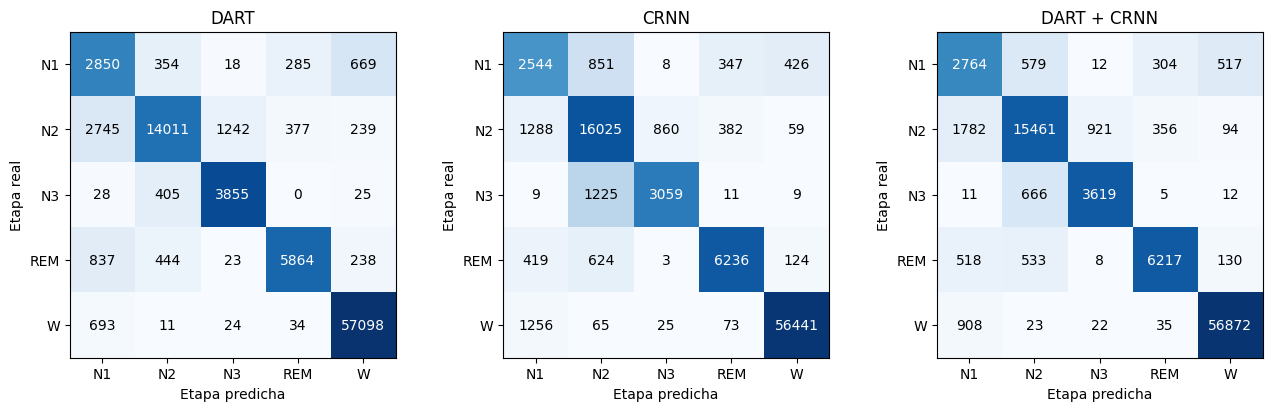

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, m in zip(axes, modelos):
    cm = confusion_matrix(test.etapa, resultados[m], labels=CLASES)
    porcentajes = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(porcentajes, vmin=0, vmax=1, cmap="Blues")
    for (i, j), n in np.ndenumerate(cm):
        ax.text(
            j,
            i,
            str(n),
            ha="center",
            va="center",
            color="white" if porcentajes[i, j] > 0.55 else "black",
        )
    ax.set(
        xticks=range(5),
        xticklabels=CLASES,
        yticks=range(5),
        yticklabels=CLASES,
        title=m,
        xlabel="Etapa predicha",
        ylabel="Etapa real",
    )
plt.show()

## Tiempos de entrenamiento

El manifiesto conserva los tiempos del ajuste publicado. La segunda columna muestra el tiempo de cada rama entrenada en esta ejecución.

In [20]:
display(
    pd.DataFrame(
        {
            "Ajuste publicado": {
                rama.upper(): f"{t:.1f} s" for rama, t in ficha_eval["tiempos_s"].items()
            },
            "Esta ejecución": {
                rama.upper(): f"{tiempos_corrida[rama]:.1f} s"
                if rama in tiempos_corrida
                else "Cargado desde disco"
                for rama in ("dart", "crnn")
            },
        }
    )
)

,Ajuste publicado,Esta ejecución
DART,1479.3 s,Cargado desde disco
CRNN,292.9 s,289.8 s


## Datos para reproducir esta corrida

Desde la raíz del repositorio actualizado, ejecuta `dvc pull` con acceso al remoto R2. Git incluye el ajuste final en `modelos/`.

El ajuste final de 100 personas está en `modelos/`. El ajuste de evaluación de 80 personas se recupera con DVC en `datos/evaluacion_80_20/`. Cada ajuste incluye `manifest.json`, `dart.txt` y `crnn.keras`. Las fichas completas para reproducir el entrenamiento están en `datos/experimentos/dart_crnn_mixto/dart_666_crnn_27_20261119_191036/entrenamiento/`.

## Cargar los modelos entrenados con el 80 % de las personas

Para omitir el entrenamiento, abre un kernel nuevo y ejecuta **únicamente la celda siguiente** después de descargar la instantánea DVC indicada arriba. Carga los pesos de DART y CRNN utilizados para producir las métricas y matrices de este informe.

El ajuste utilizó **80 personas y 158 noches** (62 personas de Cassette y 18 de Telemetry). Las otras **20 personas y 39 noches** se reservaron para la evaluación. La celda deja disponibles los modelos en dart_80 y crnn_80, el manifiesto en ficha_80 y el orden de las etapas en clases_80.

Esta versión utiliza 666 iteraciones de DART y 27 épocas de CRNN. Los pesos de la mezcla están en el campo fusion del contrato.

In [21]:
import sys
import hashlib
import json
from pathlib import Path

import lightgbm as lgb
import tensorflow as tf

raiz_80 = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / ".dvc/config").is_file())
carpeta_80 = (
    raiz_80
    / "datos/evaluacion_80_20"
)
manifiesto_80 = carpeta_80 / "manifest.json"
if not manifiesto_80.is_file():
    raise FileNotFoundError(
        "Falta el ajuste de evaluación. Ejecuta dvc pull datos/evaluacion_80_20.dvc."
    )

sys.path.insert(0, str(raiz_80 / "packages/sleep-staging/src"))
from sleep_staging.inference.mixed_bundle import read_training_manifest

ficha_80 = read_training_manifest(manifiesto_80, raiz_80 / "datos/experimentos/dart_crnn_mixto/dart_666_crnn_27_20261119_191036")
contrato_80 = ficha_80["contrato"]
firma_80 = hashlib.sha256(
    json.dumps(contrato_80, sort_keys=True, ensure_ascii=False).encode("utf8")
).hexdigest()
if (
    firma_80 != ficha_80["firma"]
    or ficha_80.get("version_experimento") != "dart_666_crnn_27_20261119_191036"
):
    raise ValueError("El manifiesto no corresponde al ajuste publicado.")
if (contrato_80["parametros_dart"]["n_estimators"], contrato_80["epocas_crnn"]) != (666, 27):
    raise ValueError("Los hiperparámetros no coinciden con los seleccionados.")

personas_80 = set(contrato_80["personas_entrenamiento"])
noches_80 = contrato_80["registros_entrenamiento"]
if (len(personas_80), len(noches_80), contrato_80["segmentos_entrenamiento"]) != (
    80,
    158,
    365283,
):
    raise ValueError("La población de entrenamiento no coincide con el ajuste 80/20.")

pesos_80 = {}
for rama in ("dart", "crnn"):
    datos_peso = ficha_80["archivos"][rama]
    ruta_peso = carpeta_80 / datos_peso["nombre"]
    if hashlib.sha256(ruta_peso.read_bytes()).hexdigest() != datos_peso["sha256"]:
        raise ValueError(f"La huella del modelo {rama} no coincide con el manifiesto.")
    pesos_80[rama] = ruta_peso

dart_80 = lgb.Booster(model_file=str(pesos_80["dart"]))
crnn_80 = tf.keras.models.load_model(pesos_80["crnn"], compile=False)
clases_80 = contrato_80["clases"]
print(
    f"DART y CRNN cargados. Entrenamiento: {len(personas_80)} personas, {len(noches_80)} noches."
)
print("Evaluación reservada: 20 personas, 39 noches. Etapas:", ", ".join(clases_80))

DART y CRNN cargados. Entrenamiento: 80 personas, 158 noches.
Evaluación reservada: 20 personas, 39 noches. Etapas: N1, N2, N3, REM, W
